# 10 Internal Review Revisions

This notebook creates V2 paper files in response to internal scientific review. It preserves the frozen 709-record analytical baseline and uses only existing verified outputs, except for the requested minimal reproduction-agreement diagnostics computed from `data/processed/dfsi_verified_baseline.csv`.

It does not run new exploratory analyses, resample Monte Carlo weights, alter analytical definitions, change priority thresholds, impute missing data or modify `data/raw`.

In [1]:
from pathlib import Path
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 160)
pd.set_option('display.max_rows', 120)
plt.style.use('seaborn-v0_8-whitegrid')

NOTEBOOK_PATH = Path.cwd()
PROJECT_ROOT = NOTEBOOK_PATH if (NOTEBOOK_PATH / 'data').exists() else NOTEBOOK_PATH.parent
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
FIGURE_DIR = PROJECT_ROOT / 'outputs' / 'figures'
PAPER_DIR = PROJECT_ROOT / 'paper'
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
PAPER_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_FILES = {
    'baseline': PROJECT_ROOT / 'data' / 'processed' / 'dfsi_verified_baseline.csv',
    'claims_v1': PAPER_DIR / 'results_claims_audit.csv',
    'verified_summary': TABLE_DIR / 'dfsi_verified_discrepancy_summary.csv',
    'verified_overlap': TABLE_DIR / 'dfsi_verified_top_group_overlap.csv',
    'component_summary': TABLE_DIR / 'dfsi_component_contribution_summary.csv',
    'loo_summary': TABLE_DIR / 'dfsi_leave_one_out_summary.csv',
    'loo_rankings': TABLE_DIR / 'dfsi_leave_one_out_rankings.csv',
    'fatality_summary': TABLE_DIR / 'fatality_exponent_summary.csv',
    'mc_summary': TABLE_DIR / 'dfsi_monte_carlo_scenario_summary.csv',
    'mc_district': TABLE_DIR / 'dfsi_monte_carlo_district_uncertainty.csv',
    'cutoff_summary': TABLE_DIR / 'dfsi_cutoff_sensitivity_summary.csv',
    'cutoff_unexpected': TABLE_DIR / 'dfsi_cutoff_unexpected_uncertainty.csv',
    'window_completeness': TABLE_DIR / 'flood_inventory_window_completeness.csv',
    'temporal_feasibility': TABLE_DIR / 'temporal_analysis_feasibility.csv',
    'join_documentation': TABLE_DIR / 'dfsi_join_documentation.csv',
    'unmatched_records': TABLE_DIR / 'dfsi_unmatched_records.csv',
    'multiply_matched_records': TABLE_DIR / 'dfsi_multiply_matched_records.csv',
}
for key, path in SOURCE_FILES.items():
    assert path.exists(), f'Missing required source: {key}: {path}'

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

RAW_HASHES_BEFORE = {path.name: sha256_file(path) for path in sorted(RAW_DIR.glob('*.csv'))}

def rel(path):
    return str(Path(path).relative_to(PROJECT_ROOT))

baseline = pd.read_csv(SOURCE_FILES['baseline'])
claims_v1 = pd.read_csv(SOURCE_FILES['claims_v1'])
verified_summary = pd.read_csv(SOURCE_FILES['verified_summary'])
verified_overlap = pd.read_csv(SOURCE_FILES['verified_overlap'])
component_summary = pd.read_csv(SOURCE_FILES['component_summary'])
loo_summary = pd.read_csv(SOURCE_FILES['loo_summary'])
loo_rankings = pd.read_csv(SOURCE_FILES['loo_rankings'])
fatality_summary = pd.read_csv(SOURCE_FILES['fatality_summary'])
mc_summary = pd.read_csv(SOURCE_FILES['mc_summary'])
mc_district = pd.read_csv(SOURCE_FILES['mc_district'])
cutoff_summary = pd.read_csv(SOURCE_FILES['cutoff_summary'])
cutoff_unexpected = pd.read_csv(SOURCE_FILES['cutoff_unexpected'])
window_completeness = pd.read_csv(SOURCE_FILES['window_completeness'])
temporal_feasibility = pd.read_csv(SOURCE_FILES['temporal_feasibility'])
join_documentation = pd.read_csv(SOURCE_FILES['join_documentation'])
unmatched_records = pd.read_csv(SOURCE_FILES['unmatched_records'])
multiply_matched_records = pd.read_csv(SOURCE_FILES['multiply_matched_records'])

complete = baseline.query("completeness_status == 'complete' and join_status == 'one_to_one_comparison_record'").copy()
assert len(complete) == 709, f'Expected frozen 709-record baseline, got {len(complete)}'
for column in ['published_dfsi', 'reconstructed_dfsi', 'published_rank', 'reconstructed_rank']:
    complete[column] = pd.to_numeric(complete[column], errors='raise').astype('float64')

print(f'Loaded frozen complete baseline: {len(complete)} records')
print('No Monte Carlo weights loaded or resampled in this notebook.')

Loaded frozen complete baseline: 709 records
No Monte Carlo weights loaded or resampled in this notebook.


## A. Minimal Reproduction-Agreement Diagnostics

The only new calculations in this V2 revision are requested agreement diagnostics between reconstructed and published DFSI scores for the frozen 709 complete records.

In [2]:
error = complete['reconstructed_dfsi'] - complete['published_dfsi']
mean_signed_error = float(error.mean())
median_signed_error = float(error.median())
rmse = float(np.sqrt(np.mean(error ** 2)))
slope, intercept = np.polyfit(complete['published_dfsi'].to_numpy(), complete['reconstructed_dfsi'].to_numpy(), deg=1)
slope = float(slope)
intercept = float(intercept)

agreement_diagnostics = pd.DataFrame([
    {'metric': 'mean_signed_error', 'value': mean_signed_error, 'unit': 'DFSI score units', 'definition': 'mean(reconstructed_dfsi - published_dfsi)'},
    {'metric': 'median_signed_error', 'value': median_signed_error, 'unit': 'DFSI score units', 'definition': 'median(reconstructed_dfsi - published_dfsi)'},
    {'metric': 'rmse', 'value': rmse, 'unit': 'DFSI score units', 'definition': 'sqrt(mean((reconstructed_dfsi - published_dfsi)^2))'},
    {'metric': 'ols_slope_reconstructed_on_published', 'value': slope, 'unit': 'slope', 'definition': 'OLS slope from np.polyfit(published_dfsi, reconstructed_dfsi, deg=1)'},
    {'metric': 'ols_intercept_reconstructed_on_published', 'value': intercept, 'unit': 'DFSI score units', 'definition': 'OLS intercept from np.polyfit(published_dfsi, reconstructed_dfsi, deg=1)'},
])
display(agreement_diagnostics)

,metric,value,unit,definition
0,mean_signed_error,-1.115266,DFSI score units,mean(reconstructed_dfsi - published_dfsi)
1,median_signed_error,-1.185715,DFSI score units,median(reconstructed_dfsi - published_dfsi)
2,rmse,1.376872,DFSI score units,sqrt(mean((reconstructed_dfsi - published_dfsi...
3,ols_slope_reconstructed_on_published,0.885496,slope,"OLS slope from np.polyfit(published_dfsi, reco..."
4,ols_intercept_reconstructed_on_published,0.441866,DFSI score units,"OLS intercept from np.polyfit(published_dfsi, ..."


## Results Claims Audit V2

The V2 claim audit retains traceability from V1 and appends the new agreement diagnostics, plus V2-specific figure/table and wording claims needed for manuscript validation.

In [3]:
claims_v2 = claims_v1.copy()
claims_v2['verification_status'] = claims_v2['verification_status'].fillna('verified')

def add_claim(claim_id, section, claim, value, unit, source_file, source_column, source_filter, notes=''):
    global claims_v2
    row = pd.DataFrame([{
        'claim_id': claim_id,
        'manuscript_section': section,
        'concise_claim': claim,
        'numerical_value': value,
        'unit_or_metric': unit,
        'source_file': source_file,
        'source_column': source_column,
        'source_row_or_filter': source_filter,
        'verification_status': 'verified',
        'notes': notes,
    }])
    claims_v2 = pd.concat([claims_v2, row], ignore_index=True)

def metric_float(name):
    row = verified_summary.loc[verified_summary['metric'].eq(name)]
    assert len(row) == 1
    return float(row.iloc[0]['value'])

def metric_int(name):
    row = verified_summary.loc[verified_summary['metric'].eq(name)]
    assert len(row) == 1
    return int(float(row.iloc[0]['value']))

def overlap(group, column):
    row = verified_overlap.loc[verified_overlap['group'].eq(group)]
    assert len(row) == 1
    return row.iloc[0][column]

def loo(component, column):
    row = loo_summary.loc[loo_summary['removed_component'].eq(component)]
    assert len(row) == 1
    return row.iloc[0][column]

def mc(scenario, column):
    row = mc_summary.loc[mc_summary['scenario'].eq(scenario)]
    assert len(row) == 1
    return row.iloc[0][column]

def cutoff(name, column):
    row = cutoff_summary.loc[cutoff_summary['cutoff'].eq(name)]
    assert len(row) == 1
    return row.iloc[0][column]

add_claim('A01', '3.1 Reproduction agreement diagnostics', 'Mean signed error', mean_signed_error, 'DFSI score units', rel(SOURCE_FILES['baseline']), 'reconstructed_dfsi; published_dfsi', "complete and one_to_one_comparison_record; reconstructed_dfsi - published_dfsi")
add_claim('A02', '3.1 Reproduction agreement diagnostics', 'Median signed error', median_signed_error, 'DFSI score units', rel(SOURCE_FILES['baseline']), 'reconstructed_dfsi; published_dfsi', "complete and one_to_one_comparison_record; reconstructed_dfsi - published_dfsi")
add_claim('A03', '3.1 Reproduction agreement diagnostics', 'RMSE', rmse, 'DFSI score units', rel(SOURCE_FILES['baseline']), 'reconstructed_dfsi; published_dfsi', "complete and one_to_one_comparison_record; sqrt(mean(error^2))")
add_claim('A04', '3.1 Reproduction agreement diagnostics', 'OLS slope for reconstructed DFSI as a function of published DFSI', slope, 'slope', rel(SOURCE_FILES['baseline']), 'reconstructed_dfsi; published_dfsi', "complete and one_to_one_comparison_record; np.polyfit")
add_claim('A05', '3.1 Reproduction agreement diagnostics', 'OLS intercept for reconstructed DFSI as a function of published DFSI', intercept, 'DFSI score units', rel(SOURCE_FILES['baseline']), 'reconstructed_dfsi; published_dfsi', "complete and one_to_one_comparison_record; np.polyfit")
add_claim('J01', '2.2 DFSI reproduction and harmonisation', 'Unmatched audit rows retained separately', int(len(unmatched_records)), 'audit rows', rel(SOURCE_FILES['unmatched_records']), 'district_review_key', 'all rows')
add_claim('J02', '2.2 DFSI reproduction and harmonisation', 'Multiply matched audit rows retained separately', int(len(multiply_matched_records)), 'audit rows', rel(SOURCE_FILES['multiply_matched_records']), 'district_review_key', 'all rows')
add_claim('L06', '3.2 Leave-one-component-out sensitivity', 'Minimum leave-one-out Spearman correlation was 0.945272', float(loo_summary['spearman_correlation_with_complete_baseline_index'].min()), 'Spearman rho', rel(SOURCE_FILES['loo_summary']), 'spearman_correlation_with_complete_baseline_index', 'minimum across removed_component rows')
add_claim('B01', '2.5 Monte Carlo weight uncertainty', 'Narrow concentration parameter is analyst-defined', float(mc('narrow','concentration')), 'Dirichlet concentration', rel(SOURCE_FILES['mc_summary']), 'concentration', "scenario == 'narrow'", 'Analyst-defined sensitivity scenario, not empirically calibrated uncertainty distribution.')
add_claim('B02', '2.5 Monte Carlo weight uncertainty', 'Moderate concentration parameter is analyst-defined', float(mc('moderate','concentration')), 'Dirichlet concentration', rel(SOURCE_FILES['mc_summary']), 'concentration', "scenario == 'moderate'", 'Primary analyst-defined sensitivity scenario, not empirically calibrated uncertainty distribution.')
add_claim('B03', '2.5 Monte Carlo weight uncertainty', 'Wide concentration parameter is analyst-defined', float(mc('wide','concentration')), 'Dirichlet concentration', rel(SOURCE_FILES['mc_summary']), 'concentration', "scenario == 'wide'", 'Analyst-defined sensitivity scenario, not empirically calibrated uncertainty distribution.')

claims_v2 = claims_v2.drop_duplicates(subset=['claim_id'], keep='last').reset_index(drop=True)
assert claims_v2['claim_id'].is_unique
claims_v2.to_csv(PAPER_DIR / 'results_claims_audit_v2.csv', index=False)
print(f'Wrote {rel(PAPER_DIR / "results_claims_audit_v2.csv")} with {len(claims_v2)} claims')
display(claims_v2.tail(12))

Wrote paper/results_claims_audit_v2.csv with 123 claims


,claim_id,manuscript_section,concise_claim,numerical_value,unit_or_metric,source_file,source_column,source_row_or_filter,verification_status,notes
111,T_window_2005-2023,3.5 Temporal limitations,2005-2023 recorded events,4126,recorded events,outputs/tables/flood_inventory_window_complete...,total_recorded_events,window == '2005-2023',verified,"Reporting volume, not physical flood frequency."
112,A01,3.1 Reproduction agreement diagnostics,Mean signed error,-1.115266,DFSI score units,data/processed/dfsi_verified_baseline.csv,reconstructed_dfsi; published_dfsi,complete and one_to_one_comparison_record; rec...,verified,
113,A02,3.1 Reproduction agreement diagnostics,Median signed error,-1.185715,DFSI score units,data/processed/dfsi_verified_baseline.csv,reconstructed_dfsi; published_dfsi,complete and one_to_one_comparison_record; rec...,verified,
114,A03,3.1 Reproduction agreement diagnostics,RMSE,1.376872,DFSI score units,data/processed/dfsi_verified_baseline.csv,reconstructed_dfsi; published_dfsi,complete and one_to_one_comparison_record; sqr...,verified,
115,A04,3.1 Reproduction agreement diagnostics,OLS slope for reconstructed DFSI as a function...,0.885496,slope,data/processed/dfsi_verified_baseline.csv,reconstructed_dfsi; published_dfsi,complete and one_to_one_comparison_record; np....,verified,
116,A05,3.1 Reproduction agreement diagnostics,OLS intercept for reconstructed DFSI as a func...,0.441866,DFSI score units,data/processed/dfsi_verified_baseline.csv,reconstructed_dfsi; published_dfsi,complete and one_to_one_comparison_record; np....,verified,
117,J01,2.2 DFSI reproduction and harmonisation,Unmatched audit rows retained separately,323,audit rows,outputs/tables/dfsi_unmatched_records.csv,district_review_key,all rows,verified,
118,J02,2.2 DFSI reproduction and harmonisation,Multiply matched audit rows retained separately,6,audit rows,outputs/tables/dfsi_multiply_matched_records.csv,district_review_key,all rows,verified,
119,L06,3.2 Leave-one-component-out sensitivity,Minimum leave-one-out Spearman correlation was...,0.945272,Spearman rho,outputs/tables/dfsi_leave_one_out_summary.csv,spearman_correlation_with_complete_baseline_index,minimum across removed_component rows,verified,
120,B01,2.5 Monte Carlo weight uncertainty,Narrow concentration parameter is analyst-defined,100.0,Dirichlet concentration,outputs/tables/dfsi_monte_carlo_scenario_summa...,concentration,scenario == 'narrow',verified,"Analyst-defined sensitivity scenario, not empi..."


## D. Revised Tables

V2 tables avoid structurally empty mixed columns. Cutoff, fatality-exponent and arithmetic component contribution outputs are supplementary tables.

In [4]:
# Table 1: reproduction summary with added agreement diagnostics.
table1_rows = [
    ['sample','one_to_one_baseline_rows',metric_int('one_to_one_comparison_rows'),'records','R01'],
    ['sample','complete_comparison_records',metric_int('complete_comparison_rows'),'records','R02'],
    ['sample','incomplete_records_preserved',metric_int('incomplete_records_preserved'),'records','R03'],
    ['range','published_dfsi_min_complete',float(complete['published_dfsi'].min()),'DFSI score','R11'],
    ['range','published_dfsi_max_complete',float(complete['published_dfsi'].max()),'DFSI score','R12'],
    ['range','reconstructed_dfsi_min_complete',float(complete['reconstructed_dfsi'].min()),'DFSI score','R09'],
    ['range','reconstructed_dfsi_max_complete',float(complete['reconstructed_dfsi'].max()),'DFSI score','R10'],
    ['correlation','pearson_correlation',metric_float('pearson_correlation'),'Pearson r','R05'],
    ['correlation','spearman_correlation',metric_float('spearman_correlation'),'Spearman rho','R04'],
    ['difference','median_absolute_numerical_difference',metric_float('median_absolute_numerical_difference'),'DFSI score units','R06'],
    ['difference','median_absolute_rank_difference',metric_float('median_absolute_rank_difference'),'rank positions','R07'],
    ['difference','maximum_absolute_rank_difference',metric_float('maximum_absolute_rank_difference'),'rank positions','R08'],
    ['agreement','mean_signed_error',mean_signed_error,'DFSI score units','A01'],
    ['agreement','median_signed_error',median_signed_error,'DFSI score units','A02'],
    ['agreement','rmse',rmse,'DFSI score units','A03'],
    ['agreement','ols_slope_reconstructed_on_published',slope,'slope','A04'],
    ['agreement','ols_intercept_reconstructed_on_published',intercept,'DFSI score units','A05'],
]
for group in ['top_25_districts','top_50_districts','top_10_percent','top_100_districts']:
    table1_rows.append(['priority_overlap', f'{group}_overlap_share', float(overlap(group,'published_overlap_share')), 'proportion', f"R{['top_25_districts','top_50_districts','top_10_percent','top_100_districts'].index(group)+13:02d}"])
    table1_rows.append(['priority_overlap', f'{group}_jaccard', float(overlap(group,'jaccard_overlap')), 'Jaccard similarity', f"R{['top_25_districts','top_50_districts','top_10_percent','top_100_districts'].index(group)+13:02d}"])
table1 = pd.DataFrame(table1_rows, columns=['category','metric','value','unit','source_claim_id'])
table1.to_csv(PAPER_DIR / 'table_1_reproduction_summary_v2.csv', index=False)

# Table 2: leave-one-out only, including p95 absolute rank change.
loo_p95 = loo_rankings.groupby('removed_component')['absolute_rank_change'].quantile(0.95).rename('p95_absolute_rank_change').reset_index()
table2 = loo_summary.merge(loo_p95, on='removed_component', how='left')[[
    'removed_component','variant_label','record_count','spearman_correlation_with_complete_baseline_index',
    'median_absolute_rank_change','p95_absolute_rank_change','maximum_absolute_rank_change',
    'top_10_percent_overlap_count','top_10_percent_overlap_share',
    'districts_entering_top_10_percent_count','districts_leaving_top_10_percent_count',
    'districts_moving_more_than_25_positions','districts_moving_more_than_50_positions'
]].copy()
table2['total_top10_turnover'] = table2['districts_entering_top_10_percent_count'] + table2['districts_leaving_top_10_percent_count']
table2.to_csv(PAPER_DIR / 'table_2_leave_one_out_summary_v2.csv', index=False)

# Table 3: Monte Carlo scenario summary only.
table3 = mc_summary.copy()
table3['scenario_definition_note'] = 'Analyst-defined Dirichlet sensitivity scenario; not empirically calibrated.'
table3.to_csv(PAPER_DIR / 'table_3_monte_carlo_scenario_summary_v2.csv', index=False)

supp_fatality = fatality_summary.copy()
supp_fatality.to_csv(PAPER_DIR / 'supplementary_table_fatality_exponent_v2.csv', index=False)

supp_cutoff = cutoff_summary.copy()
supp_cutoff['mean_overlap_share_with_baseline'] = supp_cutoff['mean_simulated_overlap_with_baseline'] / supp_cutoff['cutoff_count']
supp_cutoff['median_entering_leaving_share'] = supp_cutoff['median_number_entering_baseline_priority_group'] / supp_cutoff['cutoff_count']
supp_cutoff.to_csv(PAPER_DIR / 'supplementary_table_cutoff_sensitivity_v2.csv', index=False)

supp_component = component_summary.copy()
supp_component = supp_component.rename(columns={'median_percentage_contribution_to_total_dfsi':'median_arithmetic_share_of_additive_log_score_percent'})
supp_component.to_csv(PAPER_DIR / 'supplementary_table_component_arithmetic_v2.csv', index=False)

for path in [
    PAPER_DIR/'table_1_reproduction_summary_v2.csv', PAPER_DIR/'table_2_leave_one_out_summary_v2.csv',
    PAPER_DIR/'table_3_monte_carlo_scenario_summary_v2.csv', PAPER_DIR/'supplementary_table_fatality_exponent_v2.csv',
    PAPER_DIR/'supplementary_table_cutoff_sensitivity_v2.csv', PAPER_DIR/'supplementary_table_component_arithmetic_v2.csv'
]:
    assert path.exists() and path.stat().st_size > 0

display(table1)
display(table2)
display(table3)

,category,metric,value,unit,source_claim_id
0,sample,one_to_one_baseline_rows,720.000000,records,R01
1,sample,complete_comparison_records,709.000000,records,R02
2,sample,incomplete_records_preserved,11.000000,records,R03
3,range,published_dfsi_min_complete,4.244485,DFSI score,R11
4,range,published_dfsi_max_complete,19.300564,DFSI score,R12
5,range,reconstructed_dfsi_min_complete,5.672769,DFSI score,R09
6,range,reconstructed_dfsi_max_complete,17.948685,DFSI score,R10
7,correlation,pearson_correlation,0.958716,Pearson r,R05
8,correlation,spearman_correlation,0.958847,Spearman rho,R04
9,difference,median_absolute_numerical_difference,1.206769,DFSI score units,R06


,removed_component,variant_label,record_count,spearman_correlation_with_complete_baseline_index,median_absolute_rank_change,p95_absolute_rank_change,maximum_absolute_rank_change,top_10_percent_overlap_count,top_10_percent_overlap_share,districts_entering_top_10_percent_count,districts_leaving_top_10_percent_count,districts_moving_more_than_25_positions,districts_moving_more_than_50_positions,total_top10_turnover
0,flood_events,without flood events,709,0.979279,16.0,103.0,180,58,0.816901,13,13,206,89,26
1,mean_duration,without mean duration,709,0.992934,16.0,47.6,69,59,0.830986,12,12,229,23,24
2,fatalities,without fatalities,709,0.945272,37.0,140.0,383,57,0.802817,14,14,429,253,28
3,injured_people,without injured people,709,0.971964,25.0,95.0,214,52,0.732394,19,19,351,200,38
4,flooded_area,without flooded area,709,0.990158,16.0,55.6,117,54,0.760563,17,17,239,54,34
5,population,without population,709,0.986745,18.0,62.0,204,60,0.845070,11,11,241,73,22


,scenario,concentration,simulations,district_count,median_spearman_correlation_with_baseline_rank,spearman_correlation_p05,spearman_correlation_p95,mean_top10_overlap_with_baseline,minimum_top10_overlap_with_baseline,maximum_top10_overlap_with_baseline,median_districts_entering_leaving_baseline_top10,top10_n,robust_high_priority_districts,weight_sensitive_priority_districts,sampled_weight_sum_min,sampled_weight_sum_max,scenario_definition_note
0,narrow,100.0,10000,709,0.995934,0.988190,0.998923,63.6137,46,71,7.0,71,54.0,33.0,7.0,7.0,Analyst-defined Dirichlet sensitivity scenario...
1,moderate,30.0,10000,709,0.987768,0.963424,0.996597,58.9362,37,70,11.0,71,43.0,56.0,7.0,7.0,Analyst-defined Dirichlet sensitivity scenario...
2,wide,10.0,10000,709,0.968132,0.900572,0.990891,52.8193,27,69,17.0,71,32.0,82.0,7.0,7.0,Analyst-defined Dirichlet sensitivity scenario...


## C. Revised Figures

Figures are regenerated from existing outputs only. No simulations are rerun and no definitions or thresholds are changed.

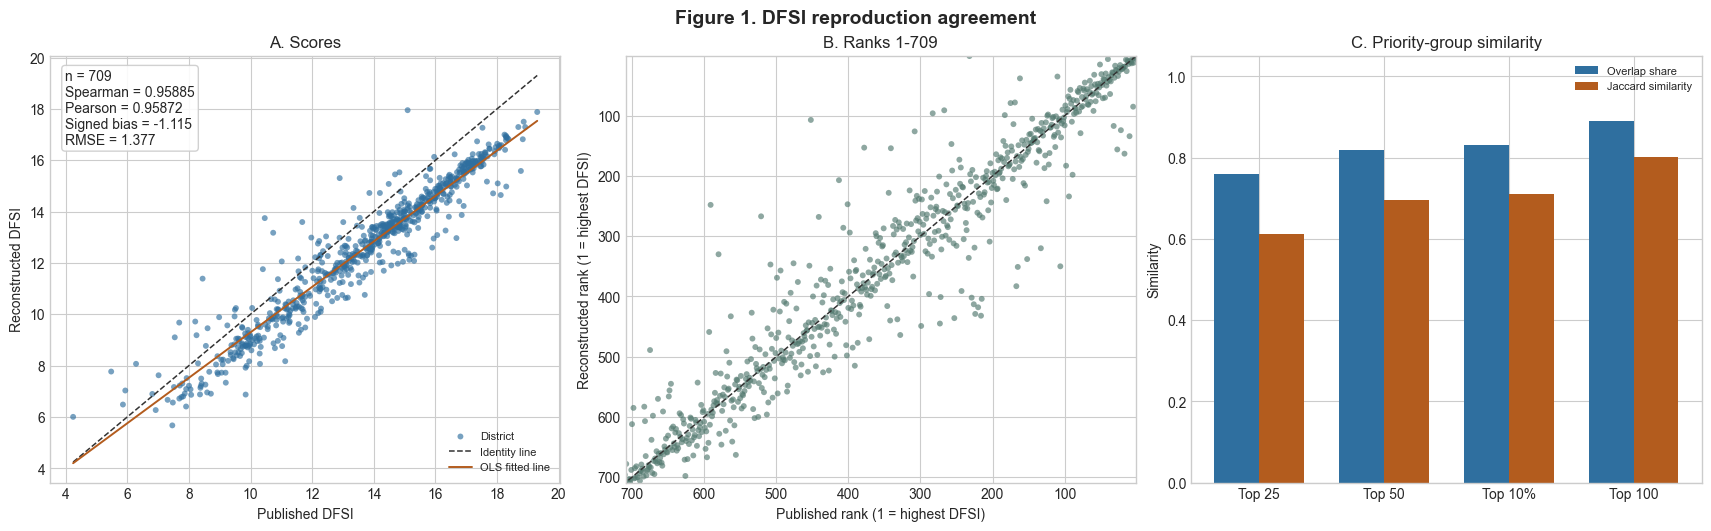

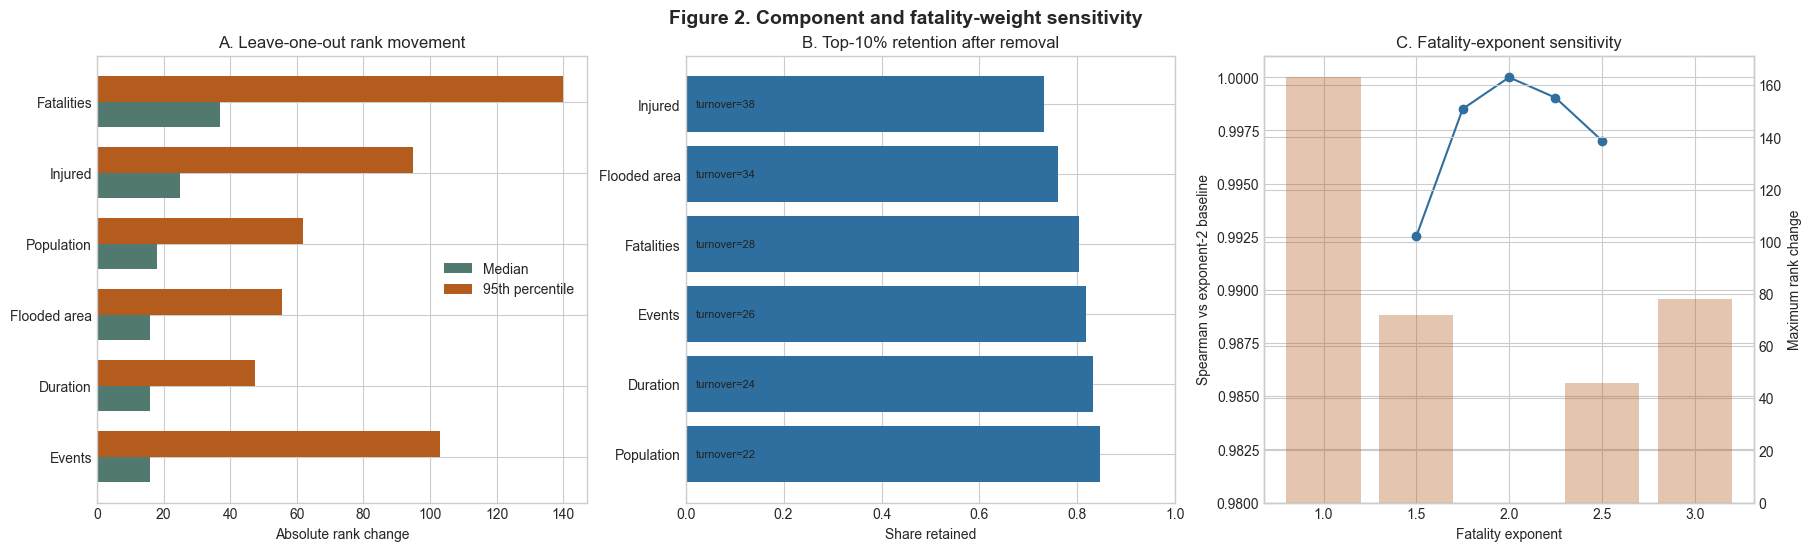

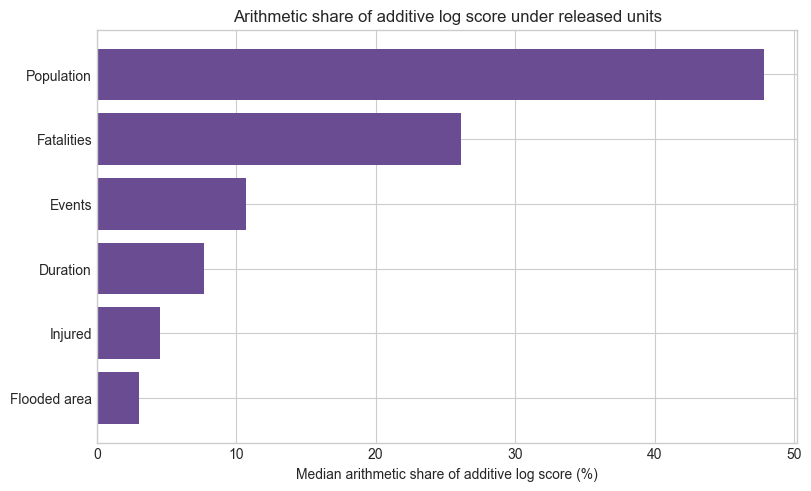

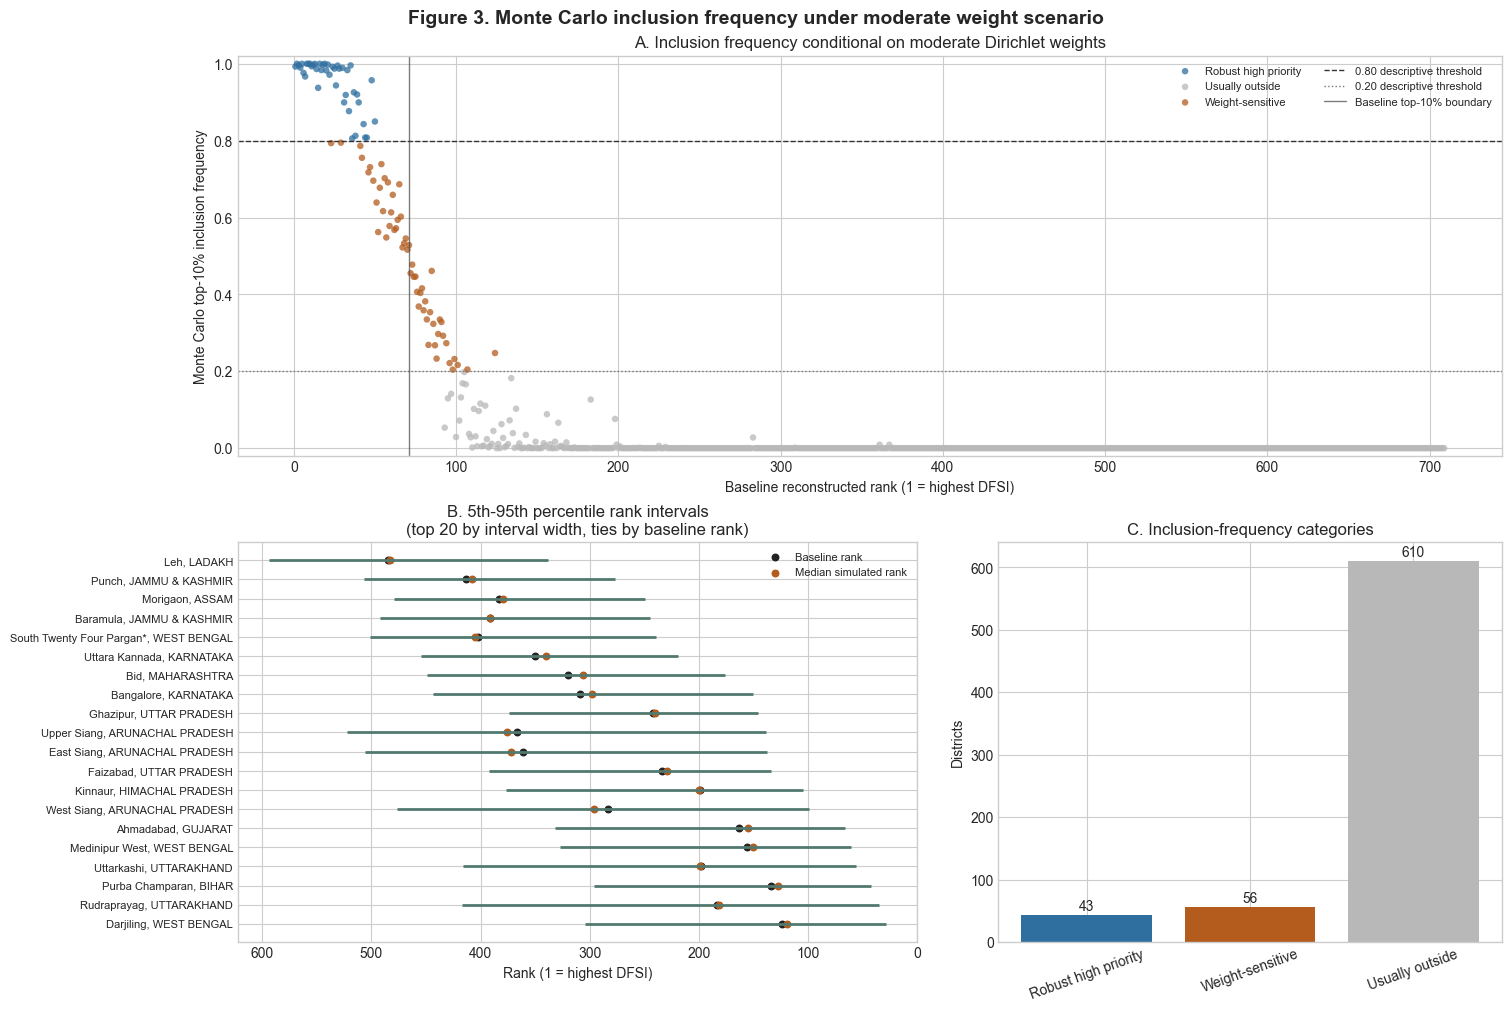

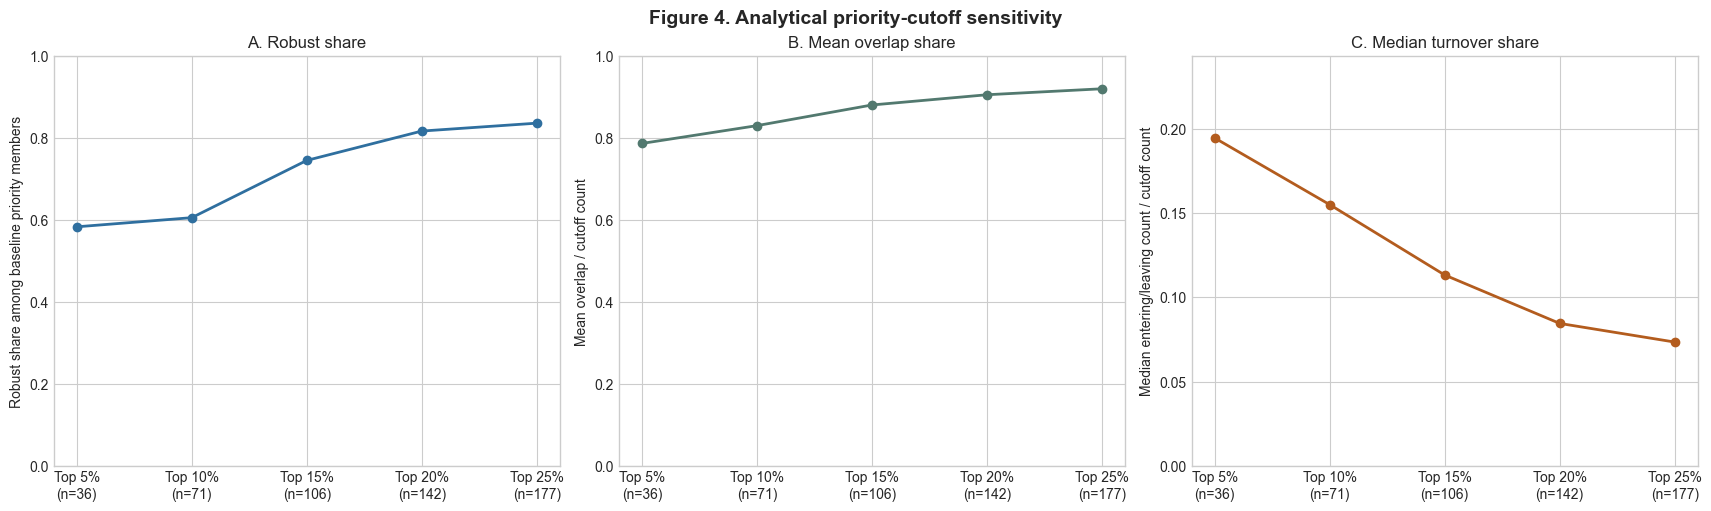

In [5]:
label_map = {
    'flood_events': 'Events',
    'mean_duration': 'Duration',
    'fatalities': 'Fatalities',
    'injured_people': 'Injured',
    'flooded_area': 'Flooded area',
    'population': 'Population',
}

# Figure 1 V2: reproduction diagnostics.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), constrained_layout=True)
axes[0].scatter(complete['published_dfsi'], complete['reconstructed_dfsi'], s=18, alpha=0.65, color='#2f6f9f', edgecolor='none', label='District')
score_min = min(complete['published_dfsi'].min(), complete['reconstructed_dfsi'].min())
score_max = max(complete['published_dfsi'].max(), complete['reconstructed_dfsi'].max())
xx = np.linspace(score_min, score_max, 100)
axes[0].plot(xx, xx, color='#333333', linestyle='--', linewidth=1.1, label='Identity line')
axes[0].plot(xx, intercept + slope * xx, color='#b35c1e', linewidth=1.4, label='OLS fitted line')
axes[0].set_xlabel('Published DFSI')
axes[0].set_ylabel('Reconstructed DFSI')
axes[0].set_title('A. Scores')
axes[0].text(0.03, 0.97, f"n = 709\nSpearman = {metric_float('spearman_correlation'):.5f}\nPearson = {metric_float('pearson_correlation'):.5f}\nSigned bias = {mean_signed_error:.3f}\nRMSE = {rmse:.3f}", transform=axes[0].transAxes, va='top', bbox={'boxstyle':'round,pad=0.25','facecolor':'white','alpha':0.9,'edgecolor':'#cccccc'})
axes[0].legend(loc='lower right', fontsize=8)

axes[1].scatter(complete['published_rank'], complete['reconstructed_rank'], s=18, alpha=0.65, color='#52796f', edgecolor='none')
axes[1].plot([1, 709], [1, 709], color='#333333', linestyle='--', linewidth=1.1)
axes[1].set_xlim(709, 1)
axes[1].set_ylim(709, 1)
axes[1].set_xlabel('Published rank (1 = highest DFSI)')
axes[1].set_ylabel('Reconstructed rank (1 = highest DFSI)')
axes[1].set_title('B. Ranks 1-709')

order = ['top_25_districts','top_50_districts','top_10_percent','top_100_districts']
ov = verified_overlap.set_index('group').loc[order].reset_index()
labels = ['Top 25','Top 50','Top 10%','Top 100']
x = np.arange(len(labels))
width = 0.36
axes[2].bar(x - width/2, ov['published_overlap_share'], width=width, color='#2f6f9f', label='Overlap share')
axes[2].bar(x + width/2, ov['jaccard_overlap'], width=width, color='#b35c1e', label='Jaccard similarity')
axes[2].set_xticks(x)
axes[2].set_xticklabels(labels)
axes[2].set_ylim(0, 1.05)
axes[2].set_ylabel('Similarity')
axes[2].set_title('C. Priority-group similarity')
axes[2].legend(fontsize=8)
fig.suptitle('Figure 1. DFSI reproduction agreement', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'paper_figure_1_dfsi_reproduction_v2.png', dpi=300, bbox_inches='tight')
plt.show()

# Figure 2 V2: component sensitivity.
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), constrained_layout=True)
loo_plot = table2.copy()
loo_plot['label'] = loo_plot['removed_component'].map(label_map)
loo_plot = loo_plot.sort_values('median_absolute_rank_change')
y = np.arange(len(loo_plot))
axes[0].barh(y - 0.18, loo_plot['median_absolute_rank_change'], height=0.36, color='#52796f', label='Median')
axes[0].barh(y + 0.18, loo_plot['p95_absolute_rank_change'], height=0.36, color='#b35c1e', label='95th percentile')
axes[0].set_yticks(y)
axes[0].set_yticklabels(loo_plot['label'])
axes[0].set_xlabel('Absolute rank change')
axes[0].set_title('A. Leave-one-out rank movement')
axes[0].legend()

turnover_plot = table2.sort_values('total_top10_turnover')
axes[1].barh(turnover_plot['removed_component'].map(label_map), turnover_plot['top_10_percent_overlap_share'], color='#2f6f9f', label='Retained top-10% share')
axes[1].set_xlim(0, 1)
axes[1].set_xlabel('Share retained')
axes[1].set_title('B. Top-10% retention after removal')
for yidx, val in enumerate(turnover_plot['total_top10_turnover']):
    axes[1].text(0.02, yidx, f'turnover={int(val)}', va='center', ha='left', fontsize=8, color='#222222')

fat_plot = fatality_summary.copy()
axes[2].plot(fat_plot['fatality_exponent'], fat_plot['spearman_correlation_with_exponent_2_baseline'], marker='o', color='#2f6f9f', label='Spearman')
axes[2].set_xlabel('Fatality exponent')
axes[2].set_ylabel('Spearman vs exponent-2 baseline')
axes[2].set_ylim(0.98, 1.001)
ax2b = axes[2].twinx()
ax2b.bar(fat_plot['fatality_exponent'].astype(str), fat_plot['maximum_rank_change'], alpha=0.35, color='#b35c1e', label='Maximum rank change')
ax2b.set_ylabel('Maximum rank change')
axes[2].set_title('C. Fatality-exponent sensitivity')
fig.suptitle('Figure 2. Component and fatality-weight sensitivity', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'paper_figure_2_component_sensitivity_v2.png', dpi=300, bbox_inches='tight')
plt.show()

# Supplementary arithmetic contribution figure requested by review.
fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
comp_plot = component_summary.copy()
comp_plot['label'] = comp_plot['component'].map(label_map)
comp_plot = comp_plot.sort_values('median_percentage_contribution_to_total_dfsi')
ax.barh(comp_plot['label'], comp_plot['median_percentage_contribution_to_total_dfsi'], color='#6a4c93')
ax.set_xlabel('Median arithmetic share of additive log score (%)')
ax.set_title('Arithmetic share of additive log score under released units')
fig.savefig(FIGURE_DIR / 'supplementary_figure_4_component_arithmetic_share_v2.png', dpi=300, bbox_inches='tight')
plt.show()

# Figure 3 V2: Monte Carlo uncertainty.
moderate = mc_district.query("scenario == 'moderate'").copy().sort_values('baseline_rank')
moderate['category_v2'] = np.select(
    [moderate['top10_probability'] >= 0.80, (moderate['top10_probability'] > 0.20) & (moderate['top10_probability'] < 0.80)],
    ['Robust high priority', 'Weight-sensitive'],
    default='Usually outside'
)
category_colors = {'Robust high priority':'#2f6f9f', 'Weight-sensitive':'#b35c1e', 'Usually outside':'#b8b8b8'}
interval_display = moderate.sort_values(['rank_p05_to_p95_interval', 'baseline_rank'], ascending=[False, True]).head(20).sort_values('rank_p05')

fig = plt.figure(figsize=(15, 10), constrained_layout=True)
gs = fig.add_gridspec(2, 2, width_ratios=[1.35, 1.0])
ax0 = fig.add_subplot(gs[0, :])
ax1 = fig.add_subplot(gs[1, 0])
ax2 = fig.add_subplot(gs[1, 1])
for category, group in moderate.groupby('category_v2'):
    ax0.scatter(group['baseline_rank'], group['top10_probability'], s=22, alpha=0.75, color=category_colors[category], edgecolor='none', label=category)
ax0.axhline(0.80, color='#333333', linestyle='--', linewidth=1, label='0.80 descriptive threshold')
ax0.axhline(0.20, color='#777777', linestyle=':', linewidth=1, label='0.20 descriptive threshold')
ax0.axvline(71, color='#444444', linewidth=1, alpha=0.7, label='Baseline top-10% boundary')
ax0.set_xlabel('Baseline reconstructed rank (1 = highest DFSI)')
ax0.set_ylabel('Monte Carlo top-10% inclusion frequency')
ax0.set_ylim(-0.02, 1.02)
ax0.set_title('A. Inclusion frequency conditional on moderate Dirichlet weights')
ax0.legend(loc='upper right', fontsize=8, ncol=2)

y = np.arange(len(interval_display))
labels = interval_display['district_name'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip() + ', ' + interval_display['State_Name'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
ax1.hlines(y, interval_display['rank_p05'], interval_display['rank_p95'], color='#52796f', linewidth=2)
ax1.scatter(interval_display['baseline_rank'], y, color='#222222', s=22, label='Baseline rank')
ax1.scatter(interval_display['median_simulated_rank'], y, color='#b35c1e', s=22, label='Median simulated rank')
ax1.set_yticks(y)
ax1.set_yticklabels(labels, fontsize=8)
ax1.invert_xaxis()
ax1.set_xlabel('Rank (1 = highest DFSI)')
ax1.set_title('B. 5th-95th percentile rank intervals\n(top 20 by interval width, ties by baseline rank)')
ax1.legend(fontsize=8)

cat_counts = moderate['category_v2'].value_counts().reindex(['Robust high priority','Weight-sensitive','Usually outside']).fillna(0)
ax2.bar(cat_counts.index, cat_counts.values, color=[category_colors[c] for c in cat_counts.index])
for i, val in enumerate(cat_counts.values):
    ax2.text(i, val + 8, str(int(val)), ha='center')
ax2.set_ylabel('Districts')
ax2.set_title('C. Inclusion-frequency categories')
ax2.tick_params(axis='x', rotation=20)
fig.suptitle('Figure 3. Monte Carlo inclusion frequency under moderate weight scenario', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'paper_figure_3_monte_carlo_uncertainty_v2.png', dpi=300, bbox_inches='tight')
plt.show()

# Figure 4 V2: cutoff sensitivity.
cut = cutoff_summary.copy()
cut['label'] = cut['cutoff'].map({'top_5pct':'Top 5%\n(n=36)','top_10pct':'Top 10%\n(n=71)','top_15pct':'Top 15%\n(n=106)','top_20pct':'Top 20%\n(n=142)','top_25pct':'Top 25%\n(n=177)'})
cut['mean_overlap_share'] = cut['mean_simulated_overlap_with_baseline'] / cut['cutoff_count']
cut['median_entering_leaving_share'] = cut['median_number_entering_baseline_priority_group'] / cut['cutoff_count']
fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
axes[0].plot(cut['label'], cut['baseline_priority_robust_proportion'], marker='o', color='#2f6f9f', linewidth=2)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Robust share among baseline priority members')
axes[0].set_title('A. Robust share')
axes[1].plot(cut['label'], cut['mean_overlap_share'], marker='o', color='#52796f', linewidth=2)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel('Mean overlap / cutoff count')
axes[1].set_title('B. Mean overlap share')
axes[2].plot(cut['label'], cut['median_entering_leaving_share'], marker='o', color='#b35c1e', linewidth=2)
axes[2].set_ylim(0, max(cut['median_entering_leaving_share']) * 1.25)
axes[2].set_ylabel('Median entering/leaving count / cutoff count')
axes[2].set_title('C. Median turnover share')
fig.suptitle('Figure 4. Analytical priority-cutoff sensitivity', fontsize=14, fontweight='bold')
fig.savefig(FIGURE_DIR / 'paper_figure_4_cutoff_sensitivity_v2.png', dpi=300, bbox_inches='tight')
plt.show()

for filename in [
    'paper_figure_1_dfsi_reproduction_v2.png', 'paper_figure_2_component_sensitivity_v2.png',
    'paper_figure_3_monte_carlo_uncertainty_v2.png', 'paper_figure_4_cutoff_sensitivity_v2.png',
    'supplementary_figure_4_component_arithmetic_share_v2.png'
]:
    path = FIGURE_DIR / filename
    assert path.exists() and path.stat().st_size > 0, path

## B. Revised Manuscript and Captions

V2 prose removes internal claim IDs, adds the DFSI equation and component definitions, clarifies joining/harmonisation, reframes Monte Carlo language and moves reporting completeness into Data Limitations.

In [6]:
placeholder = '[SOURCE DETAIL REQUIRED]'
mod = mc_district.query("scenario == 'moderate'").copy()
join_summary_lines = []
for row in join_documentation.itertuples(index=False):
    join_summary_lines.append(f"Step {int(row.join_step)} joined {row.left_dataset} to {row.right_dataset} using {row.join_keys}; join type: {row.join_type}; ambiguity policy: {row.ambiguity_policy}.")
join_summary = ' '.join(join_summary_lines)

source_detail_block = f"""
The following source details are required before submission and are not recoverable from the current project files: dataset DOI/version/access date {placeholder}; population year/source {placeholder}; flooded-area temporal definition {placeholder}; administrative-boundary vintage {placeholder}.
""".strip()

manuscript_v2 = f"""# Robust National Rankings, Uncertain Local Priorities:\nA Sensitivity Audit of India's District Flood Severity Index

# Abstract

Structured abstract placeholder.

- **Background:** Placeholder.
- **Objective:** Placeholder.
- **Methods:** Placeholder.
- **Results:** Placeholder.
- **Conclusions:** Placeholder.

# 1. Introduction

- Motivate district-level historical flood-severity prioritisation in India.
- Introduce index-based prioritisation and the need for reproducible audits.
- Distinguish national ranking reproduction from local decision stability.
- State the study objective: evaluate robustness of district prioritisation under defensible methodological alternatives.

# 2. Data and Methods

## 2.1 Data sources

The analysis used the released DFSI and component datasets preserved in the project repository, including the published DFSI table, district-level flood-impact data, district-level flooded-area data and the India Flood Inventory. Raw files were treated as immutable inputs. The final verified baseline contained 720 one-to-one comparison records, of which 709 were complete and 11 were retained as incomplete without imputation.

{source_detail_block}

## 2.2 DFSI reproduction, harmonisation and joining

The published DFSI was approximately reproduced using the released component data and an algebraically equivalent additive log-space expression. The complete expression used for reconstruction was:

```text
DFSI = log10(1 + E) + log10(1 + D) + 2*log10(1 + F) + log10(1 + I) + log10(1 + A) + log10(P)
```

where `E` is flood-event count, `D` is mean flood duration, `F` is fatalities, `I` is injured people, `A` is corrected percent flooded area under the released units and `P` is population. This additive expression is algebraically equivalent to `log10((1 + E)(1 + D)(1 + F)^2(1 + I)(1 + A)P)`.

District harmonisation used audit-preserving review keys rather than silent correction of source names. The join audit documents the following steps: {join_summary} Official LGD identifiers were preferred where available in event parsing, but the final district-level joins could not be performed solely on LGD identifiers because the summary DFSI, impact and flooded-area source tables did not all contain compatible LGD state and district codes. One-to-one comparison records were defined as records with unique review-key matches across the component sources and the published DFSI table. Unmatched and multiply matched records were retained in audit outputs rather than forced into the baseline; {len(unmatched_records)} unmatched audit rows and {len(multiply_matched_records)} multiply matched audit rows were recorded separately. The resulting baseline contained 720 one-to-one records, with 709 complete records used for numerical comparisons and 11 incomplete records preserved without imputation.

The reconstructed index was compared with the published DFSI score rather than with the published rank. Ranks were ordered in descending DFSI, so rank 1 indicates the highest score. Exact numerical reproduction was not claimed.

## 2.3 Fatality-exponent sensitivity

The published index gives fatalities an exponent of 2. To evaluate sensitivity to this design choice, alternative indices used fatality exponents of 1.0, 1.5, 2.0, 2.5 and 3.0 while leaving all other component transformations unchanged. Each variant was compared with the correctly reconstructed exponent-2 baseline, not with the published DFSI, so that the experiment isolated the fatality-weighting choice.

## 2.4 Leave-one-component-out analysis

Six leave-one-component-out variants were constructed by removing one DFSI component at a time from the reconstructed baseline. The analysis recalculated district ranks after each removal and summarized rank correlation, median, 95th-percentile and maximum absolute rank change, top-group overlap and changes in top-10% membership. Component correlations and term contributions were interpreted as descriptive diagnostics rather than causal effects.

## 2.5 Monte Carlo weight uncertainty

Monte Carlo weight uncertainty was evaluated using unweighted log terms for flood-event frequency, mean duration, fatalities, injured people, flooded area and population. Weight vectors had previously been sampled from Dirichlet distributions centred on the published weight proportions. The concentration parameters 100, 30 and 10 are analyst-defined sensitivity scenarios and are not empirically calibrated uncertainty distributions. The moderate uncertainty scenario is treated as the primary analysis because it remains centred on the published weighting structure while permitting meaningful methodological variation.

Districts were categorized using Monte Carlo top-10% inclusion frequency, equivalently a simulation-based inclusion probability conditional on the specified Dirichlet weight distribution. Robust high-priority districts had inclusion frequency >= 0.80, weight-sensitive districts had inclusion frequency > 0.20 and < 0.80, and usually-outside districts had inclusion frequency <= 0.20. The 0.20 and 0.80 values are descriptive reporting thresholds, not universal policy standards.

## 2.6 Analytical priority-cutoff sensitivity

Analytical priority-cutoff sensitivity tested whether conclusions depended on selecting the top 10% as the priority group. The saved moderate-scenario Monte Carlo outputs were evaluated under fixed cutoffs of top 5%, top 10%, top 15%, top 20% and top 25%, corresponding to 36, 71, 106, 142 and 177 districts. The analysis reported robust membership, weight-sensitive membership and baseline priority districts with inclusion frequency below 0.80.

## 2.7 Evaluation metrics and reporting thresholds

The study reports Pearson correlation for numerical agreement and Spearman correlation for ranking agreement. Rank differences are absolute differences in descending ranks. Priority-group overlap is reported as both overlap share and Jaccard similarity. Monte Carlo inclusion categories use the descriptive thresholds 0.20 and 0.80.

## 2.8 Data limitations and historical reporting completeness

The India Flood Inventory was audited for historical reporting volume and completeness over the period 1967-2023. This audit is treated as a data-limitation and supplementary analysis rather than as a main historical trend result. Recorded event counts were treated as reporting volume and were not interpreted as physical flood-frequency trends. A complete period-specific DFSI could not be reconstructed from the event inventory alone because flooded-area percentage and population were not available as period-specific components and because historical reporting coverage was uneven.

# 3. Results

## 3.1 Reproduction of the published DFSI

The verified reproduction used 709 complete district records from 720 one-to-one baseline records, while preserving 11 incomplete records without imputation. The reconstructed DFSI ranged from {complete['reconstructed_dfsi'].min():.4f} to {complete['reconstructed_dfsi'].max():.4f}, while the published DFSI among complete records ranged from {complete['published_dfsi'].min():.4f} to {complete['published_dfsi'].max():.4f}. The reconstructed index strongly reproduced the published ranking, with Spearman correlation {metric_float('spearman_correlation'):.5f} and Pearson correlation {metric_float('pearson_correlation'):.5f}. However, exact numerical reproduction was not achieved: the median absolute numerical difference was {metric_float('median_absolute_numerical_difference'):.5f}, the median absolute rank difference was {metric_float('median_absolute_rank_difference'):.0f} positions and the maximum absolute rank difference was {metric_float('maximum_absolute_rank_difference'):.0f} positions.

Additional agreement diagnostics showed a mean signed error of {mean_signed_error:.5f}, a median signed error of {median_signed_error:.5f} and RMSE of {rmse:.5f}. An ordinary least-squares fit of reconstructed DFSI as a function of published DFSI had slope {slope:.5f} and intercept {intercept:.5f}. Published-versus-reconstructed overlap shares were {overlap('top_25_districts','published_overlap_share'):.1%} for the top 25, {overlap('top_50_districts','published_overlap_share'):.1%} for the top 50, {overlap('top_10_percent','published_overlap_share'):.1%} for the top 10% and {overlap('top_100_districts','published_overlap_share'):.1%} for the top 100.

## 3.2 Component and leave-one-out sensitivity

Leave-one-component-out analysis showed that removing fatalities produced the largest median absolute rank change, {loo('fatalities','median_absolute_rank_change'):.0f} positions, and a maximum absolute rank change of {loo('fatalities','maximum_absolute_rank_change'):.0f} positions. Removing injured people produced the largest top-10% membership turnover, with {loo('injured_people','districts_entering_top_10_percent_count'):.0f} districts entering and {loo('injured_people','districts_leaving_top_10_percent_count'):.0f} leaving the group. The minimum leave-one-out Spearman correlation was {loo_summary['spearman_correlation_with_complete_baseline_index'].min():.6f}, observed when fatalities were removed. Thus, high national rank correlation can coexist with substantial district-level movement.

Fatality-exponent sensitivity produced high rank correlations with the reconstructed exponent-2 baseline, but individual district movements remained nontrivial. Reducing the exponent to 1.0 gave Spearman correlation {float(fatality_summary.loc[fatality_summary['fatality_exponent'].eq(1.0),'spearman_correlation_with_exponent_2_baseline'].iloc[0]):.4f}, median absolute rank change {float(fatality_summary.loc[fatality_summary['fatality_exponent'].eq(1.0),'median_absolute_rank_change'].iloc[0]):.0f}, maximum rank change {float(fatality_summary.loc[fatality_summary['fatality_exponent'].eq(1.0),'maximum_rank_change'].iloc[0]):.0f} and top-10% overlap {float(fatality_summary.loc[fatality_summary['fatality_exponent'].eq(1.0),'top_10_percent_overlap_count'].iloc[0]):.0f} of 71 districts.

## 3.3 Monte Carlo uncertainty in district prioritisation

In the primary moderate uncertainty scenario, {int(mc('moderate','simulations'))} saved Monte Carlo weight vectors were evaluated for 709 complete districts. The median Spearman correlation with the baseline ranking was {float(mc('moderate','median_spearman_correlation_with_baseline_rank')):.4f}, but top-priority membership remained sensitive. Conditional on the specified moderate Dirichlet weight distribution, the scenario identified {int(mc('moderate','robust_high_priority_districts'))} robust high-priority districts, {int(mc('moderate','weight_sensitive_priority_districts'))} weight-sensitive districts and {int((mod['top10_probability'] <= 0.20).sum())} usually-outside districts. Among baseline top-10% districts, {int((mod['baseline_top10'] & mod['top10_probability'].lt(0.80)).sum())} had less than 0.80 Monte Carlo top-10% inclusion frequency. Thus, national ranking stability did not guarantee district-level decision stability.

## 3.4 Sensitivity to the analytical priority cutoff

Priority instability persisted across all five analytical priority thresholds examined. The proportion of baseline priority districts classified as robust was {cutoff('top_5pct','baseline_priority_robust_proportion'):.1%} for the top 5%, {cutoff('top_10pct','baseline_priority_robust_proportion'):.1%} for the top 10%, {cutoff('top_15pct','baseline_priority_robust_proportion'):.1%} for the top 15%, {cutoff('top_20pct','baseline_priority_robust_proportion'):.1%} for the top 20% and {cutoff('top_25pct','baseline_priority_robust_proportion'):.1%} for the top 25%. The largest number of weight-sensitive districts was {int(cutoff_summary['cutoff_sensitive_districts'].max())}, observed under the top-10%, top-15%, top-20% and top-25% thresholds. These results indicate that the central conclusion does not depend on using the top-10% threshold.

# 4. Discussion

- Interpret strong national rank reproduction alongside non-exact numerical reproduction.
- Discuss why decisions based on priority-group membership require more than rank correlation.
- Discuss component-weight uncertainty as a transparent robustness problem.
- Discuss implications for district prioritisation and communication of uncertainty.
- Discuss limitations of static population/flooded-area components and historical reporting completeness.

# 5. Conclusion

- The released datasets approximately reproduce the published DFSI ranking.
- District-level priority membership is sensitive to reasonable methodological alternatives.
- Robust prioritisation should report inclusion frequencies and analytical cutoff sensitivity, not only national rank correlations.
- Temporal claims require explicit reporting-completeness caveats.

# Data and Code Availability

Placeholder. Data and analysis code availability statement to be completed after repository and dataset citation details are finalized.

# References

- Original DFSI paper placeholder.
- Zenodo dataset placeholder.
"""
(PAPER_DIR / 'manuscript_v2.md').write_text(manuscript_v2, encoding='utf-8')

figure_captions_v2 = """# Figure Captions V2

**Figure 1. DFSI reproduction agreement.** Published DFSI scores and ranks are compared with the verified reconstructed DFSI for 709 complete one-to-one district records. Ranks are ordered from 1 to 709 in descending DFSI, so rank 1 represents the highest DFSI. The score panel shows both the identity line and an ordinary least-squares fitted line for reconstructed DFSI as a function of published DFSI. Annotations report Spearman correlation, Pearson correlation, signed bias and RMSE. Priority-group similarity is reported as overlap share and Jaccard similarity rather than raw counts.

**Figure 2. Component and fatality-weight sensitivity.** Leave-one-component-out results are shown for the 709 complete district records. Panel A reports median and 95th-percentile absolute rank change; panel B reports top-10% retention and turnover after component removal; panel C reports fatality-exponent sensitivity relative to the reconstructed exponent-2 baseline. Component correlations and rank changes are descriptive and should not be interpreted as causal effects.

**Figure 3. Monte Carlo inclusion frequency under moderate weight scenario.** The primary moderate uncertainty scenario evaluates Monte Carlo top-10% inclusion frequency among 709 complete district records. Results are conditional on the specified Dirichlet weight distribution. Robust high-priority districts have inclusion frequency >= 0.80, weight-sensitive districts have inclusion frequency > 0.20 and < 0.80, and usually-outside districts have inclusion frequency <= 0.20. The 0.20 and 0.80 values are descriptive reporting thresholds. Rank intervals are 5th-95th percentile simulated ranks, and displayed districts are selected reproducibly as the 20 districts with the widest interval, breaking ties by baseline rank.

**Figure 4. Analytical priority-cutoff sensitivity.** The moderate scenario is evaluated under fixed analytical cutoffs of top 5% (36 districts), top 10% (71), top 15% (106), top 20% (142) and top 25% (177). Panel A reports robust share among baseline priority members, panel B reports mean overlap divided by cutoff count, and panel C reports median entering/leaving count divided by cutoff count.

**Supplementary Figure 4. Arithmetic share of additive log score under released units.** This figure reports the median arithmetic share of each additive log-score term under the released units. It is a descriptive arithmetic decomposition, not a measure of causal importance or decision influence.
"""
(PAPER_DIR / 'figure_captions_v2.md').write_text(figure_captions_v2, encoding='utf-8')

table_captions_v2 = """# Table Captions V2

**Table 1. Reproduction summary.** Summary of verified DFSI reproduction using the frozen 709 complete one-to-one district records, with 11 incomplete records retained separately. The table reports score ranges, correlations, numerical differences, rank differences, agreement diagnostics, overlap shares and Jaccard similarities. Ranks are descending, so rank 1 is highest DFSI.

**Table 2. Leave-one-out summary.** Summary of leave-one-component-out sensitivity for the 709 complete district records. The table reports Spearman correlation with the complete reconstructed baseline, median, 95th-percentile and maximum absolute rank change, top-10% retention and turnover.

**Table 3. Monte Carlo scenario summary.** Summary of narrow, moderate and wide analyst-defined Dirichlet sensitivity scenarios. Concentration parameters 100, 30 and 10 are not empirically calibrated uncertainty distributions. The moderate scenario is the primary scenario.

**Supplementary Table. Fatality-exponent sensitivity.** Summary of alternative fatality exponents compared with the reconstructed exponent-2 baseline.

**Supplementary Table. Cutoff sensitivity.** Summary of fixed analytical priority cutoffs from top 5% to top 25%, including robust share, overlap share and turnover share.

**Supplementary Table. Arithmetic component contribution.** Descriptive arithmetic shares of the additive log score under the released units. These are not causal importance estimates.
"""
(PAPER_DIR / 'table_captions_v2.md').write_text(table_captions_v2, encoding='utf-8')

for path in [PAPER_DIR/'manuscript_v2.md', PAPER_DIR/'figure_captions_v2.md', PAPER_DIR/'table_captions_v2.md']:
    assert path.exists() and path.stat().st_size > 0
print('Wrote V2 manuscript and captions.')

Wrote V2 manuscript and captions.


## E. Validation and Revision Log

In [7]:
manuscript_text = (PAPER_DIR / 'manuscript_v2.md').read_text(encoding='utf-8')
figure_caption_text = (PAPER_DIR / 'figure_captions_v2.md').read_text(encoding='utf-8')
table_caption_text = (PAPER_DIR / 'table_captions_v2.md').read_text(encoding='utf-8')

# Required wording and scientific-review validations.
assert 'All leave-one-component-out variants retained Spearman correlations above 0.95' not in manuscript_text
assert 'corrected additive log-space expression' not in manuscript_text
assert 'algebraically equivalent additive log-space expression' in manuscript_text
assert 'DFSI = log10(1 + E)' in manuscript_text
assert manuscript_text.count('[SOURCE DETAIL REQUIRED]') >= 4
assert 'Claims ' not in manuscript_text and 'Claim ' not in manuscript_text
assert 'policy-priority cutoff' not in manuscript_text
assert 'policy-priority group' not in manuscript_text
assert 'flood risk' not in manuscript_text.lower()
assert 'Monte Carlo top-10% inclusion frequency' in manuscript_text
assert 'conditional on the specified moderate Dirichlet weight distribution' in manuscript_text or 'conditional on the specified Dirichlet weight distribution' in manuscript_text
assert 'analyst-defined sensitivity scenarios and are not empirically calibrated uncertainty distributions' in manuscript_text
assert 'The minimum leave-one-out Spearman correlation was 0.945272' in manuscript_text

# Claim traceability: all key numerical claims in V2 prose are present in audit V2 or direct source tables.
claims_text = pd.read_csv(PAPER_DIR / 'results_claims_audit_v2.csv')
for claim_id in ['R01','R02','R03','R04','R05','R06','R07','R08','A01','A02','A03','A04','A05','L06','MC_moderate_robust','MC_moderate_sensitive','MC03','P01','P02','T01','T02']:
    assert claim_id in set(claims_text['claim_id']), f'Missing traceability claim {claim_id}'

# No new simulation/resampling validation: this notebook reads saved scenario summaries and district uncertainty only.
# It does not load sampled Monte Carlo weights or call random-number generators.
registered_sources = '\n'.join(str(path) for path in SOURCE_FILES.values())
assert 'dfsi_monte_carlo_sampled_weights.csv' not in registered_sources
assert 'mc_summary' in SOURCE_FILES and 'mc_district' in SOURCE_FILES

RAW_HASHES_AFTER = {path.name: sha256_file(path) for path in sorted(RAW_DIR.glob('*.csv'))}
assert RAW_HASHES_BEFORE == RAW_HASHES_AFTER, 'data/raw hashes changed.'

revision_log = f"""# Internal Revision Log

Created by `notebooks/10_internal_review_revisions.ipynb`.

## Scope Controls

- Preserved the frozen 709-record analytical baseline.
- Did not run new exploratory analyses.
- Did not resample Monte Carlo weights or load sampled-weight vectors.
- Did not alter analytical definitions, priority thresholds or missing-data handling.
- Verified that `data/raw` file hashes were unchanged.

## Reproduction Diagnostics Added

- Added mean signed error: {mean_signed_error:.6f} DFSI score units.
- Added median signed error: {median_signed_error:.6f} DFSI score units.
- Added RMSE: {rmse:.6f} DFSI score units.
- Added OLS slope for reconstructed DFSI as a function of published DFSI: {slope:.6f}.
- Added OLS intercept: {intercept:.6f} DFSI score units.
- Added these values to `paper/results_claims_audit_v2.csv` with claim IDs A01-A05.

## Manuscript Revisions

- Replaced the phrase "corrected additive log-space expression" with "algebraically equivalent additive log-space expression".
- Added the complete DFSI equation and definitions for flood-event count, mean duration, fatalities, injured people, corrected percent flooded area and population.
- Added [SOURCE DETAIL REQUIRED] placeholders for dataset DOI/version/access date, population year/source, flooded-area temporal definition and administrative-boundary vintage.
- Expanded district harmonisation and joining methods using existing join-audit outputs.
- Clarified one-to-one construction, unmatched records, multiply matched records, the 720 baseline rows, 709 complete records and 11 incomplete records.
- Replaced unqualified probability language with Monte Carlo inclusion frequency and simulation-based inclusion probability conditional on the specified Dirichlet weight distribution.
- Stated that concentration parameters 100, 30 and 10 are analyst-defined sensitivity scenarios and not empirically calibrated uncertainty distributions.
- Replaced policy-priority cutoff language with analytical priority cutoff language.
- Preferred historical flood severity wording and removed unsupported flood-risk phrasing.
- Moved reporting-completeness audit material into a concise Data Limitations subsection and supplementary framing.
- Removed internal claim IDs from `paper/manuscript_v2.md`.
- Corrected Results 3.2 to report the minimum leave-one-out Spearman correlation as 0.945272 rather than claiming all leave-one-out correlations exceed 0.95.

## Figure Revisions

- Created `outputs/figures/paper_figure_1_dfsi_reproduction_v2.png` with score and rank scatterplots, ranks 1-709, identity and fitted lines, signed bias and RMSE, and overlap/Jaccard summaries.
- Created `outputs/figures/paper_figure_2_component_sensitivity_v2.png` with median and 95th-percentile rank changes, top-10% retention/turnover and fatality-exponent sensitivity.
- Created `outputs/figures/paper_figure_3_monte_carlo_uncertainty_v2.png` with Monte Carlo top-10% inclusion frequency, point-category legend, 5th-95th percentile rank intervals and a reproducible district display rule.
- Created `outputs/figures/paper_figure_4_cutoff_sensitivity_v2.png` with robust share, mean overlap share and median turnover share across analytical priority cutoffs.
- Created `outputs/figures/supplementary_figure_4_component_arithmetic_share_v2.png` for arithmetic component contribution under released units.

## Table Revisions

- Created `paper/table_1_reproduction_summary_v2.csv`.
- Created `paper/table_2_leave_one_out_summary_v2.csv`.
- Created `paper/table_3_monte_carlo_scenario_summary_v2.csv`.
- Created `paper/supplementary_table_fatality_exponent_v2.csv`.
- Created `paper/supplementary_table_cutoff_sensitivity_v2.csv`.
- Created `paper/supplementary_table_component_arithmetic_v2.csv`.
- Avoided structurally empty mixed tables by separating reproduction, leave-one-out, Monte Carlo, fatality-exponent, cutoff and arithmetic-contribution outputs.

## Validation Results

- V2 manuscript numerical claims are traceable through `paper/results_claims_audit_v2.csv` and the existing source CSVs.
- No V2 manuscript statement says all leave-one-out Spearman values exceed 0.95.
- Monte Carlo inclusion results are explicitly conditional on the assumed Dirichlet weight distribution.
- No new simulation or exploratory analysis was run.
- `data/raw` hashes were unchanged.
"""
(PAPER_DIR / 'internal_revision_log.md').write_text(revision_log, encoding='utf-8')

for path in [
    PAPER_DIR/'results_claims_audit_v2.csv', PAPER_DIR/'manuscript_v2.md', PAPER_DIR/'figure_captions_v2.md',
    PAPER_DIR/'table_captions_v2.md', PAPER_DIR/'internal_revision_log.md',
    PAPER_DIR/'table_1_reproduction_summary_v2.csv', PAPER_DIR/'table_2_leave_one_out_summary_v2.csv',
    PAPER_DIR/'table_3_monte_carlo_scenario_summary_v2.csv', PAPER_DIR/'supplementary_table_fatality_exponent_v2.csv',
    PAPER_DIR/'supplementary_table_cutoff_sensitivity_v2.csv', PAPER_DIR/'supplementary_table_component_arithmetic_v2.csv',
    FIGURE_DIR/'paper_figure_1_dfsi_reproduction_v2.png', FIGURE_DIR/'paper_figure_2_component_sensitivity_v2.png',
    FIGURE_DIR/'paper_figure_3_monte_carlo_uncertainty_v2.png', FIGURE_DIR/'paper_figure_4_cutoff_sensitivity_v2.png',
    FIGURE_DIR/'supplementary_figure_4_component_arithmetic_share_v2.png'
]:
    assert path.exists() and path.stat().st_size > 0, path

print('Internal review V2 validation passed.')
print('V2 files created:')
for path in [
    PAPER_DIR/'results_claims_audit_v2.csv', PAPER_DIR/'manuscript_v2.md', PAPER_DIR/'figure_captions_v2.md',
    PAPER_DIR/'table_captions_v2.md', PAPER_DIR/'internal_revision_log.md',
    PAPER_DIR/'table_1_reproduction_summary_v2.csv', PAPER_DIR/'table_2_leave_one_out_summary_v2.csv',
    PAPER_DIR/'table_3_monte_carlo_scenario_summary_v2.csv', PAPER_DIR/'supplementary_table_fatality_exponent_v2.csv',
    PAPER_DIR/'supplementary_table_cutoff_sensitivity_v2.csv', PAPER_DIR/'supplementary_table_component_arithmetic_v2.csv',
    FIGURE_DIR/'paper_figure_1_dfsi_reproduction_v2.png', FIGURE_DIR/'paper_figure_2_component_sensitivity_v2.png',
    FIGURE_DIR/'paper_figure_3_monte_carlo_uncertainty_v2.png', FIGURE_DIR/'paper_figure_4_cutoff_sensitivity_v2.png',
    FIGURE_DIR/'supplementary_figure_4_component_arithmetic_share_v2.png'
]:
    print(f'- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)')

Internal review V2 validation passed.
V2 files created:
- paper/results_claims_audit_v2.csv (27,946 bytes)
- paper/manuscript_v2.md (12,344 bytes)
- paper/figure_captions_v2.md (2,518 bytes)
- paper/table_captions_v2.md (1,481 bytes)
- paper/internal_revision_log.md (4,305 bytes)
- paper/table_1_reproduction_summary_v2.csv (1,814 bytes)
- paper/table_2_leave_one_out_summary_v2.csv (1,108 bytes)
- paper/table_3_monte_carlo_scenario_summary_v2.csv (1,117 bytes)
- paper/supplementary_table_fatality_exponent_v2.csv (1,053 bytes)
- paper/supplementary_table_cutoff_sensitivity_v2.csv (1,212 bytes)
- paper/supplementary_table_component_arithmetic_v2.csv (2,107 bytes)
- outputs/figures/paper_figure_1_dfsi_reproduction_v2.png (713,905 bytes)
- outputs/figures/paper_figure_2_component_sensitivity_v2.png (315,106 bytes)
- outputs/figures/paper_figure_3_monte_carlo_uncertainty_v2.png (612,061 bytes)
- outputs/figures/paper_figure_4_cutoff_sensitivity_v2.png (243,546 bytes)
- outputs/figures/supple